# CoT × 推理深度 — Pilot（Kaggle 版）

用几百道小程序题，在 10 分钟内验证三件事。

| 段 | 问题 | 产出 |
|---|---|---|
| **S1** | 模型能算对**一步**吗？ | 选一个合适的模数 |
| **S2** | 从第几步开始算错？ | 找到准确率 30–50% 的深度区间 |
| **S3** | 让它写推理过程，准确率会变好吗？ | 第一版 Δ–d 曲线（可以进 proposal）|

---

## 运行前必做（两件事）

1. 右上角 **Settings → Accelerator → GPU T4 x2**
2. 右上角 **Settings → Internet → On** ← 不开的话下载不了模型

然后**从上往下依次运行**（Run All 也行，但 S2/S3 要按 S1 的结果改 `MOD`）。

## 你会得到什么

- `pilot_recs.jsonl`：每条生成记录一行（**追加写入，不会覆盖**）
- 三张表 + 一张 Δ–d 图
- 每题都可以回看模型的原始输出，方便 debug


In [1]:
import os, sys, json, re, random, subprocess, collections

# ============ 配置（只改这里）============
MODEL_NAME = 'Qwen/Qwen3-1.7B'   # 换 4B: 'Qwen/Qwen3-4B'
AMAX       = 12                   # 单步运算第二个操作数的上限
MAX_TOKENS = 768                  # CoT 最多生成多少 token
OUTDIR     = '/kaggle/working' if os.path.isdir('/kaggle/working') else '.'
OUT_PATH   = os.path.join(OUTDIR, 'pilot_recs.jsonl')
# ========================================

os.environ['HF_HOME'] = '/tmp/hf'          # 别放 /kaggle/working，会吃满 20GB 配额
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['CUDA_VISIBLE_DEVICES'] = '0'   # 双卡不要切分模型，只用一张

subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-U',
                'transformers>=4.51', 'accelerate'], check=False)

import torch, transformers
print('transformers', transformers.__version__)
print('torch', torch.__version__)
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f'GPU: {p.name} | VRAM {p.total_memory/1e9:.1f} GB | bf16: {torch.cuda.is_bf16_supported()}')
else:
    print('!!! 没有 GPU —— 去 Settings 里打开 Accelerator !!!')
print('输出目录:', OUTDIR)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 32.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 29.7 MB/s eta 0:00:00
transformers 5.20.1
torch 2.11.0+cu128
GPU: Tesla T4 | VRAM 15.6 GB | bf16: True
输出目录: /kaggle/working


In [2]:
from transformers import AutoModelForCausalLM, AutoTokenizer

# T4 / P100 是 Turing 架构，不支持 bf16，会自动降到 fp16
DTYPE = torch.bfloat16 if (torch.cuda.is_available() and torch.cuda.is_bf16_supported()) else torch.float16
print('dtype =', DTYPE)

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
tok.padding_side = 'left'          # 批量生成必须左填充
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

try:
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=DTYPE, device_map='auto')
except TypeError:                  # 老版本 transformers 用 torch_dtype
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=DTYPE, device_map='auto')
model.eval()
print('loaded:', MODEL_NAME)

dtype = torch.bfloat16


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

loaded: Qwen/Qwen3-1.7B


In [4]:
MOD_DEFAULT = 97

def _apply(y, kind, a, mod):
    if kind == '+': return (y + a) % mod
    if kind == '-': return (y - a) % mod
    return (y * a) % mod          # 注意：模运算里没有除法，只用 + - *

def _draw(rng, n, amax):
    return [(rng.choice('+-*'), rng.randrange(2, amax + 1)) for _ in range(n)]

def make_serial(rng, d, mod=MOD_DEFAULT, amax=AMAX):
    '''串行链：深度 d，工作量 W = d（每一步都依赖上一步）'''
    x = rng.randrange(2, mod)
    ops = _draw(rng, d, amax)
    y = x
    for k, a in ops:
        y = _apply(y, k, a, mod)
    body = '\n'.join(f'{i+1}. ( {k} {a} )' for i, (k, a) in enumerate(ops))
    q = (f'Start with x = {x}. Apply the following operations IN ORDER, where all '
         f'arithmetic is modulo {mod} (take the remainder after dividing by {mod}).\n'
         f'{body}\nWhat is the final value of x?')
    return dict(q=q, ans=y, d=d, W=d, kind='serial')

def make_parallel(rng, w, mod=MOD_DEFAULT, amax=AMAX):
    '''并行：w 个互不依赖的运算 + 合并，深度恒为 2，W = 2w-1'''
    x = rng.randrange(2, mod)
    ops = _draw(rng, w, amax)
    vals = [_apply(x, k, a, mod) for k, a in ops]
    ans = sum(vals) % mod
    body = '\n'.join(f'{i+1}. ( {k} {a} )' for i, (k, a) in enumerate(ops))
    q = (f'Start with x = {x}. Apply EACH of the following operations separately to x, '
         f'all arithmetic modulo {mod}. Then add all the results together and take the '
         f'result modulo {mod}.\n{body}\nWhat is the final value?')
    return dict(q=q, ans=ans, d=2, W=2 * w - 1, kind='parallel')

print('generator ready')

generator ready


In [5]:
ex = make_serial(random.Random(0), 3)
print('=== 生成的题目（d=3，必须一步一步算）===')
print(ex['q'])
print()
print('脚本自己算出的正确答案:', ex['ans'])
print()
print('=== 并行版（同样 3 个运算，但互相不依赖）===')
print(make_parallel(random.Random(0), 3)['q'])

=== 生成的题目（d=3，必须一步一步算）===
Start with x = 51. Apply the following operations IN ORDER, where all arithmetic is modulo 97 (take the remainder after dividing by 97).
1. ( - 2 )
2. ( - 10 )
3. ( - 8 )
What is the final value of x?

脚本自己算出的正确答案: 31

=== 并行版（同样 3 个运算，但互相不依赖）===
Start with x = 51. Apply EACH of the following operations separately to x, all arithmetic modulo 97. Then add all the results together and take the result modulo 97.
1. ( - 2 )
2. ( - 10 )
3. ( - 8 )
What is the final value?


In [6]:
SYS_DA  = ('You are a precise calculator. Compute the result silently and output only '
           'the final number. Do not explain your steps.')
SYS_COT = ('You are a precise calculator. Work through the arithmetic step by step, '
           'showing each intermediate value, then state the final number.')
SUFFIX  = '\nEnd your reply with exactly: Final answer: <number>'
NUMRE   = re.compile(r'Final answer:[ ]*[*]*[ ]*(-?[0-9]+)', re.I)

def extract(txt):
    m = NUMRE.search(txt)
    if m: return int(m.group(1))
    nums = re.findall(r'-?[0-9]+', txt)
    return int(nums[-1]) if nums else None

def build_prompt(system, user):
    msgs = [{'role': 'system', 'content': system},
            {'role': 'user', 'content': user + SUFFIX}]
    try:                          # Qwen3 默认开 thinking，这里显式关掉
        return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True,
                                       enable_thinking=False)
    except (TypeError, ValueError):
        return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

@torch.no_grad()
def infer(items, systems, max_tokens=MAX_TOKENS, batch=8, verbose=True):
    prompts, meta = [], []
    for it in items:
        for name, sysm in systems.items():
            prompts.append(build_prompt(sysm, it['q']))
            meta.append((name, it))
    recs = []
    for i in range(0, len(prompts), batch):
        chunk = prompts[i:i + batch]
        enc = tok(chunk, return_tensors='pt', padding=True).to(model.device)
        out = model.generate(**enc, max_new_tokens=max_tokens, do_sample=False,
                             pad_token_id=tok.pad_token_id)
        gen = out[:, enc['input_ids'].shape[1]:]
        for j, g in enumerate(gen):
            txt = tok.decode(g, skip_special_tokens=True)
            name, it = meta[i + j]
            pred = extract(txt)
            recs.append(dict(cond=name, kind=it['kind'], d=it['d'], W=it['W'],
                             ans=it['ans'], pred=pred, ok=int(pred == it['ans']),
                             ntok=int(g.shape[-1]), text=txt))
        if verbose:
            print(f'  {min(i + batch, len(prompts))}/{len(prompts)}', end='\r')
    if verbose: print()
    return recs

In [7]:
import pandas as pd

def save(recs):
    with open(OUT_PATH, 'a', encoding='utf-8') as f:
        for r in recs:
            f.write(json.dumps(r, ensure_ascii=False) + '\n')
    print(f'saved {len(recs)} records -> {OUT_PATH}')

def report(recs, group=('kind', 'd', 'cond')):
    agg = collections.defaultdict(list)
    for r in recs:
        agg[tuple(r[g] for g in group)].append(r)
    rows = []
    for k in sorted(agg, key=lambda t: tuple(str(x) for x in t)):
        rs = agg[k]
        row = dict(zip(group, k))
        row['n'] = len(rs)
        row['acc'] = round(sum(r['ok'] for r in rs) / len(rs), 3)
        row['ntok'] = round(sum(r['ntok'] for r in rs) / len(rs), 1)
        row['parse_fail'] = round(sum(1 for r in rs if r['pred'] is None) / len(rs), 3)
        rows.append(row)
    return pd.DataFrame(rows)

## S1 · 模型能算对一步吗？

用三个模数各 10 道 `d=1` 的题，只看 DA 条件。

- 准确率 **60–90%** → 用这个模数，进 S2
- 全 **>95%** → 太简单，把 `AMAX` 调到 40 重跑
- 全 **<40%** → 太难，试 `mod=11`


In [8]:
rng = random.Random(1)
items = [make_serial(rng, 1, mod=m) for m in (97, 13, 11) for _ in range(10)]
recs_s1 = infer(items, {'DA': SYS_DA}, max_tokens=64)
save(recs_s1)

rows = []
for it, r in zip(items, recs_s1):
    rows.append({'mod': int(re.search(r'modulo ([0-9]+)', it['q']).group(1)), 'ok': r['ok']})
print('=== S1 各模数准确率 ===')
display(pd.DataFrame(rows).groupby('mod')['ok'].agg(['mean', 'count']))

  30/30
saved 30 records -> /kaggle/working/pilot_recs.jsonl
=== S1 各模数准确率 ===


,mean,count
mod,,
11,0.4,10
13,0.6,10
97,0.8,10


## S2 · 从第几步开始算错？

**先按 S1 的结果改下面的 `MOD`**，然后运行。只看 DA 条件。

目标：找到准确率掉到 **30–50%** 的那个 `d`。它就是正式实验的中心。


In [10]:
MOD    = 97                                  # <-- 按 S1 结果改这里
DEPTHS = (1, 2, 3, 4, 6, 8, 10)

rng = random.Random(2)
items = [make_serial(rng, d, mod=MOD) for d in DEPTHS for _ in range(10)]
recs_s2 = infer(items, {'DA': SYS_DA}, max_tokens=128)
save(recs_s2)
print(f'=== S2 深度阶梯（mod={MOD}，只看 DA）===')
display(report(recs_s2, group=('d', 'cond')))

  70/70
saved 70 records -> /kaggle/working/pilot_recs.jsonl
=== S2 深度阶梯（mod=97，只看 DA）===


,d,cond,n,acc,ntok,parse_fail
0,1,DA,10,0.8,67.2,0.0
1,10,DA,10,0.0,51.8,0.0
2,2,DA,10,0.8,104.0,0.0
3,3,DA,10,0.6,85.4,0.0
4,4,DA,10,0.0,112.2,0.0
5,6,DA,10,0.1,102.2,0.0
6,8,DA,10,0.0,104.6,0.0


## S3 · 写推理过程会让准确率变好吗？（+ 并行对照）

同一个模型、同一批题，只改系统提示：

- **DA**：只输出最终数字
- **CoT**：一步一步写出中间值

**并行对照**是整件事的地基：同样数量的运算，但互不依赖。如果 CoT 只在**串行**题上有效，说明它补的确实是「串行计算能力」；如果两版一样，说明我们测到的只是「题目变难了」。


In [10]:
DEPTHS = (2, 4, 6, 8)
N      = 20

rng = random.Random(3)
items  = [make_serial(rng, d, mod=MOD) for d in DEPTHS for _ in range(N)]
items += [make_parallel(rng, w, mod=MOD) for w in (3, 5) for _ in range(N)]

recs_s3 = infer(items, {'DA': SYS_DA, 'CoT': SYS_COT})
save(recs_s3)
print('=== S3 明细 ===')
display(report(recs_s3))

rows = []
for kind in ('serial', 'parallel'):
    for d in sorted({r['d'] for r in recs_s3 if r['kind'] == kind}):
        a = [r['ok'] for r in recs_s3 if r['kind'] == kind and r['d'] == d and r['cond'] == 'DA']
        b = [r['ok'] for r in recs_s3 if r['kind'] == kind and r['d'] == d and r['cond'] == 'CoT']
        if a and b:
            rows.append({'kind': kind, 'd': d,
                         'DA': round(sum(a) / len(a), 3),
                         'CoT': round(sum(b) / len(b), 3),
                         'Delta': round(sum(b) / len(b) - sum(a) / len(a), 3)})
delta_df = pd.DataFrame(rows)
print('=== Delta = CoT - DA ===')
display(delta_df)

  240/240
saved 240 records -> /kaggle/working/pilot_recs.jsonl
=== S3 明细 ===


,kind,d,cond,n,acc,ntok,parse_fail
0,parallel,2,CoT,40,0.350,364.8,0.0
1,parallel,2,DA,40,0.075,364.8,0.1
2,serial,2,CoT,20,0.950,151.2,0.0
3,serial,2,DA,20,0.800,151.2,0.0
4,serial,4,CoT,20,0.950,236.0,0.0
5,serial,4,DA,20,0.200,236.0,0.0
6,serial,6,CoT,20,0.700,338.4,0.0
7,serial,6,DA,20,0.050,338.4,0.0
8,serial,8,CoT,20,0.750,453.6,0.0
9,serial,8,DA,20,0.000,453.6,0.0


=== Delta = CoT - DA ===


,kind,d,DA,CoT,Delta
0,serial,2,0.800,0.95,0.150
1,serial,4,0.200,0.95,0.750
2,serial,6,0.050,0.70,0.650
3,serial,8,0.000,0.75,0.750
4,parallel,2,0.075,0.35,0.275


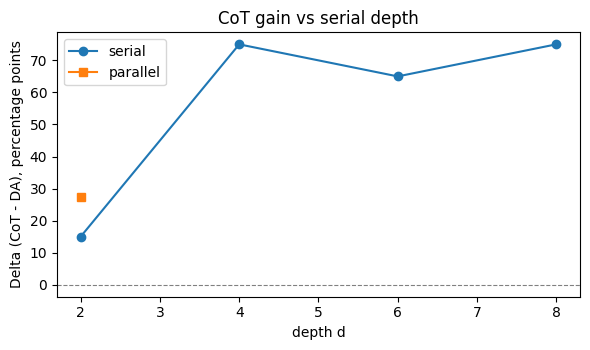

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3.6))
for kind, marker in [('serial', 'o'), ('parallel', 's')]:
    sub = delta_df[delta_df.kind == kind].sort_values('d')
    if len(sub):
        ax.plot(sub.d, sub.Delta * 100, marker=marker, label=kind)
ax.axhline(0, color='gray', lw=0.8, ls='--')
ax.set_xlabel('depth d')
ax.set_ylabel('Delta (CoT - DA), percentage points')
ax.set_title('CoT gain vs serial depth')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, 'delta_vs_depth.png'), dpi=150)
plt.show()

## 回看原始输出（debug 用）

如果准确率全是 0，先看这里。三种典型问题：

1. **模型没按格式输出** → `parse_fail` 高，且这里看不到 `Final answer:`
2. **CoT 和 DA 一样短** → 提示词没生效，模型没真的一步步写
3. **CoT 的 `ntok` 顶到 768** → 被截断了，把 `MAX_TOKENS` 调大


In [12]:
for r in recs_s3[:2] + [x for x in recs_s3 if x['cond'] == 'CoT'][:2]:
    print('-' * 70)
    print(f"cond={r['cond']} d={r['d']} ans={r['ans']} pred={r['pred']} ntok={r['ntok']}")
    print(r['text'][:700])

----------------------------------------------------------------------
cond=DA d=2 ans=36 pred=36 ntok=148
1. (32 * 10) mod 97 = 320 mod 97 = 320 - 3*97 = 320 - 291 = 29
2. (29 + 7) mod 97 = 36 mod 97 = 36

Final answer: 36
----------------------------------------------------------------------
cond=CoT d=2 ans=36 pred=36 ntok=148
Start with $ x = 32 $.

1. Multiply by 10:  
   $ x = 32 \times 10 = 320 $

2. Add 7:  
   $ x = 320 + 7 = 327 $

Now, take the remainder modulo 97:  
$ 327 \mod 97 = 327 - 3 \times 97 = 327 - 291 = 36 $

Final answer: 36
----------------------------------------------------------------------
cond=CoT d=2 ans=36 pred=36 ntok=148
Start with $ x = 32 $.

1. Multiply by 10:  
   $ x = 32 \times 10 = 320 $

2. Add 7:  
   $ x = 320 + 7 = 327 $

Now, take the remainder modulo 97:  
$ 327 \mod 97 = 327 - 3 \times 97 = 327 - 291 = 36 $

Final answer: 36
----------------------------------------------------------------------
cond=CoT d=2 ans=7 pred=104 ntok=148
Start wi

## 结果怎么读

### S3 的 Delta 表

| 你看到的 | 含义 | 下一步 |
|---|---|---|
| serial 的 Delta 随 d 上升，parallel 接近 0 | ✅ **假设成立** | 这张图直接进 proposal |
| 两者都接近 0，且 DA 准确率很高 | 任务太简单 | 把 `AMAX` 调到 40，或把 `DEPTHS` 加大 |
| 两者都接近 0，且 DA 准确率接近 0 | 任务太难 | `MOD` 降成 11 或 13，`DEPTHS` 改成 (1,2,3,4,5) |
| DA 和 CoT 的 `ntok` 差不多 | ⚠️ 提示词没生效，实验作废 | 检查 `SYS_DA` / `SYS_COT` 有没有被 chat template 吃掉 |
| `parse_fail` 明显大于 0 | 抽取失败 | 看「回看原始输出」那节，改 `NUMRE` |

### 把结果发回来

请贴这三样：
1. S1 的模数准确率表
2. S2 的深度阶梯表
3. S3 的 Delta 表和那张图

有了这三样就能定：正式实验的 `d` 范围、`MAX_TOKENS` 要多少、以及这张图能不能进 proposal。

### 注意

这是 **pilot**，样本量很小，结论只能用来定参数、**不能写进报告当结论**。
所有记录都在 `pilot_recs.jsonl` 里，是追加写入的，多跑几次不会丢数据。


In [11]:
# ============ v2：DA 硬截断 + W 配平 + 真实 ntok ============
EOS = tok.eos_token_id

def infer2(items, systems, cap, batch=8):
    prompts, meta = [], []
    for it in items:
        for name, sysm in systems.items():
            prompts.append(build_prompt(sysm, it['q']))
            meta.append((name, it))
    recs = []
    for i in range(0, len(prompts), batch):
        enc = tok(prompts[i:i+batch], return_tensors='pt', padding=True).to(model.device)
        mx = max(cap[m] for m, _ in meta[i:i+batch])
        out = model.generate(**enc, max_new_tokens=mx, do_sample=False, pad_token_id=EOS)
        gen = out[:, enc['input_ids'].shape[1]:]
        for j in range(gen.shape[0]):
            ids = gen[j].tolist()
            L = ids.index(EOS) if EOS in ids else len(ids)
            txt = tok.decode(ids[:L], skip_special_tokens=True)
            name, it = meta[i+j]
            pred = extract(txt)
            recs.append(dict(cond=name, kind=it['kind'], d=it['d'], W=it['W'],
                             ans=it['ans'], pred=pred, ok=int(pred==it['ans']),
                             ntok=L, text=txt))
    return recs

def analyse(recs):
    rows = []
    for kind, d in sorted({(r['kind'], r['d']) for r in recs}):
        a = [r['ok'] for r in recs if r['kind']==kind and r['d']==d and r['cond']=='DA']
        b = [r['ok'] for r in recs if r['kind']==kind and r['d']==d and r['cond']=='CoT']
        if not a or not b: continue
        da, cot = sum(a)/len(a), sum(b)/len(b)
        rows.append(dict(kind=kind, d=d, W=(lambda r: r['W'])(next(r for r in recs
                    if r['kind']==kind and r['d']==d)), n=len(a),
                    DA=round(da,3), CoT=round(cot,3), Delta=round(cot-da,3),
                    err_cut=round(1-(1-cot)/(1-da),3) if da < 1 else None))
    return pd.DataFrame(rows)

# W 配平：串行 d 对应 并行 w，使 d == 2w-1
pairs = [(3,2), (5,3), (7,4), (9,5)]
rng = random.Random(7)
items = []
for d, w in pairs:
    items += [make_serial(rng, d, mod=MOD) for _ in range(20)]
    items += [make_parallel(rng, w, mod=MOD) for _ in range(20)]

recs_v2 = infer2(items, {'DA': SYS_DA, 'CoT': SYS_COT}, {'DA': 32, 'CoT': 768})
save(recs_v2)
display(analyse(recs_v2))

saved 320 records -> /kaggle/working/pilot_recs.jsonl


,kind,d,W,n,DA,CoT,Delta,err_cut
0,parallel,2,3,80,0.163,0.263,0.10,0.119
1,serial,3,3,20,0.500,0.950,0.45,0.900
2,serial,5,5,20,0.250,0.900,0.65,0.867
3,serial,7,7,20,0.000,0.750,0.75,0.750
4,serial,9,9,20,0.000,0.700,0.70,0.700
